In [8]:
import pandas as  pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [9]:
df = pd.read_csv("/content/loan_sanction_test (1)  s.csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,LP001015,Male,Yes,0,Graduate,No,5720,0,110.0,360.0,1.0,Urban
1,LP001022,Male,Yes,1,Graduate,No,3076,1500,126.0,360.0,1.0,Urban
2,LP001031,Male,Yes,2,Graduate,No,5000,1800,208.0,360.0,1.0,Urban
3,LP001035,Male,Yes,2,Graduate,No,2340,2546,100.0,360.0,NaN,Urban
4,LP001051,Male,No,0,Not Graduate,No,3276,0,78.0,360.0,1.0,Urban


In [10]:
df.shape

(367, 12)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 367 entries, 0 to 366
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            367 non-null    object 
 1   Gender             356 non-null    object 
 2   Married            367 non-null    object 
 3   Dependents         357 non-null    object 
 4   Education          367 non-null    object 
 5   Self_Employed      344 non-null    object 
 6   ApplicantIncome    367 non-null    int64  
 7   CoapplicantIncome  367 non-null    int64  
 8   LoanAmount         362 non-null    float64
 9   Loan_Amount_Term   361 non-null    float64
 10  Credit_History     338 non-null    float64
 11  Property_Area      367 non-null    object 
dtypes: float64(3), int64(2), object(7)
memory usage: 34.5+ KB


In [12]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,367.000000,367.000000,362.000000,361.000000,338.000000
mean,4805.599455,1569.577657,136.132597,342.537396,0.825444
std,4910.685399,2334.232099,61.366652,65.156643,0.380150
min,0.000000,0.000000,28.000000,6.000000,0.000000
25%,2864.000000,0.000000,100.250000,360.000000,1.000000
50%,3786.000000,1025.000000,125.000000,360.000000,1.000000
75%,5060.000000,2430.500000,158.000000,360.000000,1.000000
max,72529.000000,24000.000000,550.000000,480.000000,1.000000


In [13]:
df.isnull().sum()

,0
Loan_ID,0
Gender,11
Married,0
Dependents,10
Education,0
Self_Employed,23
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,5
Loan_Amount_Term,6


In [16]:
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])
df['Married'] = df['Married'].fillna(df['Married'].mode()[0])
df['Dependents'] = df['Dependents'].fillna(df['Dependents'].mode()[0])
df['Self_Employed'] = df['Self_Employed'].fillna(df['Self_Employed'].mode()[0])
df['Loan_Amount_Term'] = df['Loan_Amount_Term'].fillna(df['Loan_Amount_Term'].mode()[0])
df['Credit_History'] = df['Credit_History'].fillna(df['Credit_History'].mode()[0])

In [17]:
df['LoanAmount'] = df['LoanAmount'].fillna(df['LoanAmount'].median())


In [18]:
df.isnull().sum()

,0
Loan_ID,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0


Text(0.5, 0, 'Income')

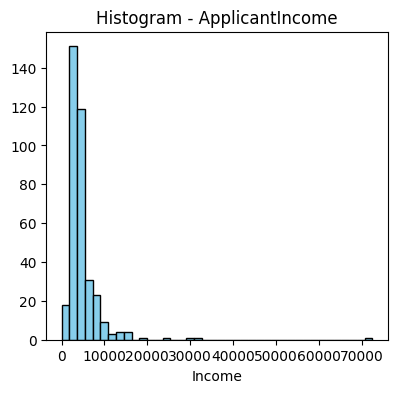

In [20]:
plt.figure(figsize=(15,4))
plt.subplot(1,3,1)
plt.hist(df['ApplicantIncome'], bins=40, color='skyblue', edgecolor='black')
plt.title('Histogram - ApplicantIncome')
plt.xlabel('Income')

Text(0.5, 0, 'Loan Amount')

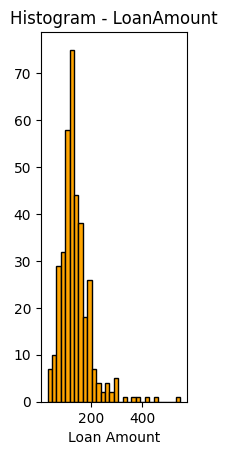

In [21]:
plt.subplot(1,3,2)
plt.hist(df['LoanAmount'], bins=30, color='orange', edgecolor='black')
plt.title('Histogram - LoanAmount')
plt.xlabel('Loan Amount')

Text(0.5, 1.0, 'Histogram - CoapplicantIncome')

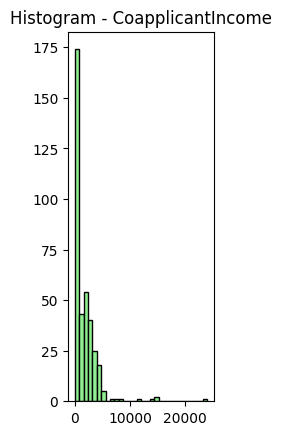

In [22]:
plt.subplot(1,3,3)
plt.hist(df['CoapplicantIncome'], bins=30, color='lightgreen', edgecolor='black')
plt.title('Histogram - CoapplicantIncome')


In [27]:
plt.tight_layout()
plt.show()


<Figure size 640x480 with 0 Axes>

 Histogram (ApplicantIncome, LoanAmount)

 ApplicantIncome ka distribution right-skewed hai, matlab jyadatar applicants ki income 3000-5000 ke beech hai, lekin kuch high-income outliers bhi hain (25000+). LoanAmount ka data bhi 100-200 ke beech concentrated hai.

In [28]:
plt.figure(figsize=(12,8))

<Figure size 1200x800 with 0 Axes>

<Figure size 1200x800 with 0 Axes>

Text(0.5, 1.0, 'Bar Chart - Gender')

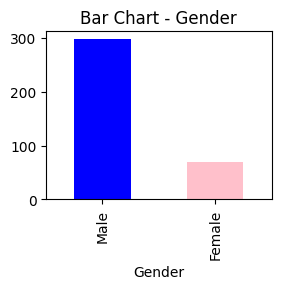

In [30]:
plt.subplot(2,2,1)
df['Gender'].value_counts().plot(kind='bar', color=['blue','pink'])
plt.title('Bar Chart - Gender')

Text(0.5, 1.0, 'Bar Chart - Married')

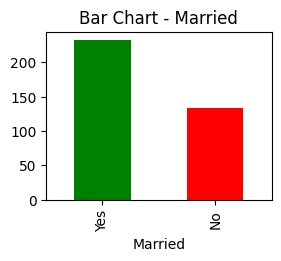

In [31]:

plt.subplot(2,2,2)
df['Married'].value_counts().plot(kind='bar', color=['green','red'])
plt.title('Bar Chart - Married')


Text(0.5, 1.0, 'Bar Chart - Education')

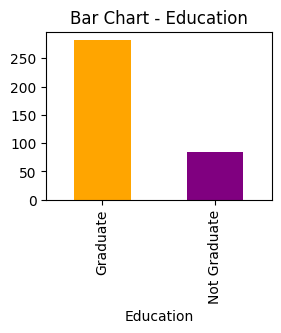

In [32]:
plt.subplot(2,2,3)
df['Education'].value_counts().plot(kind='bar', color=['orange','purple'])
plt.title('Bar Chart - Education')

Text(0.5, 1.0, 'Bar Chart - Property_Area')

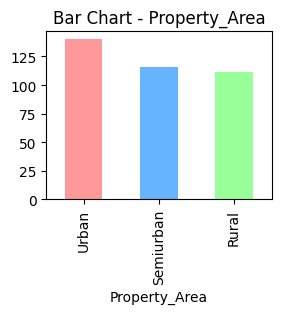

In [33]:
plt.subplot(2,2,4)
df['Property_Area'].value_counts().plot(kind='bar', color=['#ff9999','#66b3ff','#99ff99'])
plt.title('Bar Chart - Property_Area')


In [34]:

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

Box Plot (Outliers):

Box plot se pata chala ki ApplicantIncome aur LoanAmount me outliers present hain. Income me bahut zyada values (outliers) hain jo analysis ko affect kar sakti hain, isliye data cleaning ki zarurat hai.

In [35]:
plt.figure(figsize=(12,4))


<Figure size 1200x400 with 0 Axes>

<Figure size 1200x400 with 0 Axes>

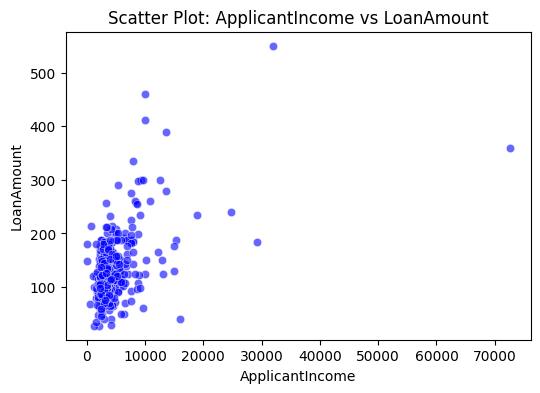

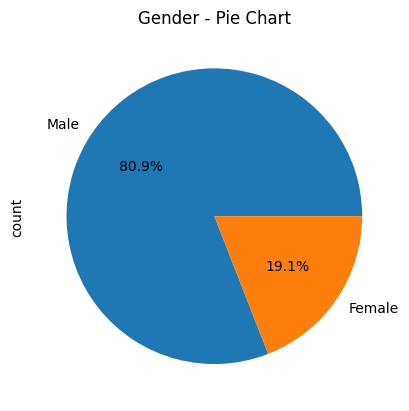

In [39]:
plt.figure(figsize=(6,4))
sns.scatterplot(x='ApplicantIncome', y='LoanAmount', data=df, color='blue', alpha=0.6)
plt.title('Scatter Plot: ApplicantIncome vs LoanAmount')
plt.xlabel('ApplicantIncome')
plt.ylabel('LoanAmount')
plt.show()
df['Gender'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title('Gender - Pie Chart')
plt.show()

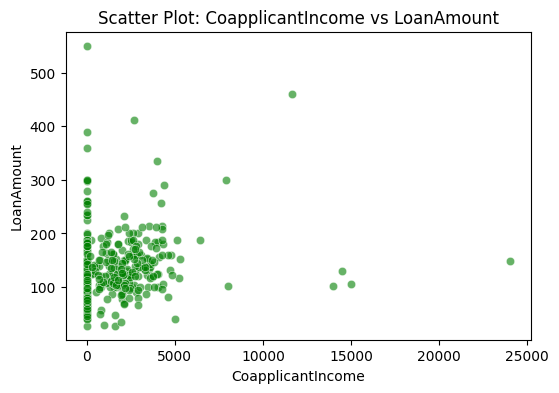

In [40]:
plt.figure(figsize=(6,4))
sns.scatterplot(x='CoapplicantIncome', y='LoanAmount', data=df, color='green', alpha=0.6)
plt.title('Scatter Plot: CoapplicantIncome vs LoanAmount')
plt.show()

1. Scatter Plot (ApplicantIncome vs LoanAmount):

The scatter plot shows a weak relationship between ApplicantIncome and LoanAmount. Higher income does not always guarantee a higher loan amount. Even low-income applicants have received high loan amounts, which indicates that other factors like Credit_History are more important.

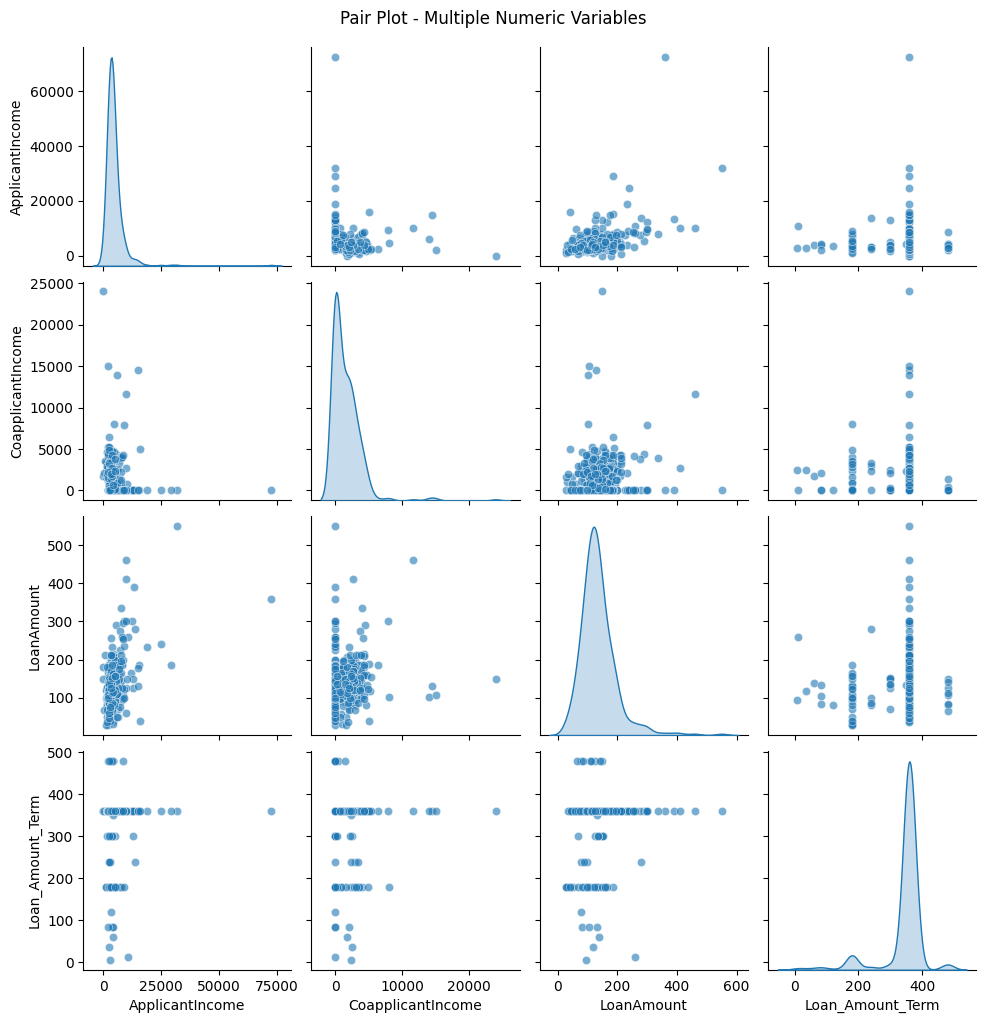

In [41]:
numeric_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']
sns.pairplot(df[numeric_cols], diag_kind='kde', plot_kws={'alpha':0.6})
plt.suptitle('Pair Plot - Multiple Numeric Variables', y=1.02)
plt.show()

 Pair Plot (Scatter Matrix):

 The pair plot shows no strong linear correlation between any of the numerical variables. The relationship between ApplicantIncome, CoapplicantIncome, and LoanAmount is weak, suggesting these variables alone cannot determine the loan amount.

/tmp/ipykernel_1740/3985168971.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Education', y='ApplicantIncome', data=df, palette='Set2')


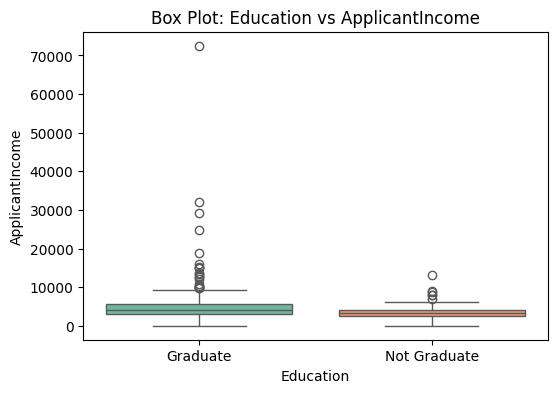

In [42]:
plt.figure(figsize=(6,4))
sns.boxplot(x='Education', y='ApplicantIncome', data=df, palette='Set2')
plt.title('Box Plot: Education vs ApplicantIncome')
plt.show()


/tmp/ipykernel_1740/1063277807.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Property_Area', y='LoanAmount', data=df, palette='pastel')


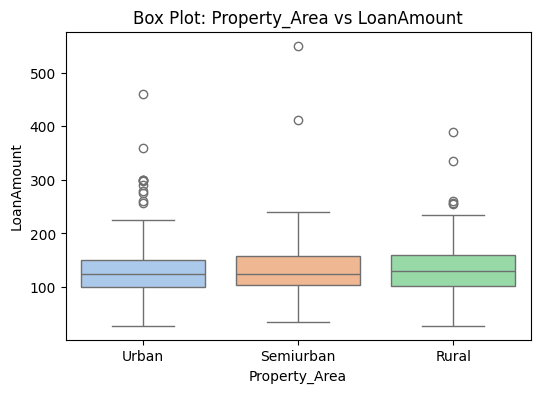

In [43]:
plt.figure(figsize=(6,4))
sns.boxplot(x='Property_Area', y='LoanAmount', data=df, palette='pastel')
plt.title('Box Plot: Property_Area vs LoanAmount')
plt.show()


/tmp/ipykernel_1740/535868748.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Gender', y='LoanAmount', data=df, palette='muted')


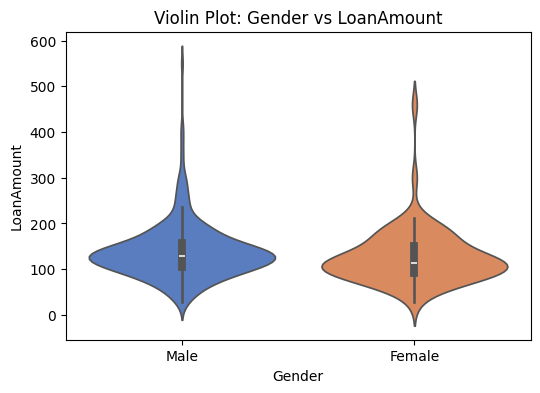

In [44]:
plt.figure(figsize=(6,4))
sns.violinplot(x='Gender', y='LoanAmount', data=df, palette='muted')
plt.title('Violin Plot: Gender vs LoanAmount')
plt.show()

/tmp/ipykernel_1740/3851169445.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Married', y='ApplicantIncome', data=df, palette='rocket')


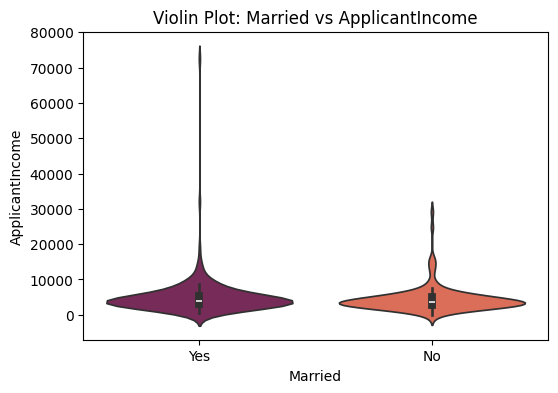

In [45]:
plt.figure(figsize=(6,4))
sns.violinplot(x='Married', y='ApplicantIncome', data=df, palette='rocket')
plt.title('Violin Plot: Married vs ApplicantIncome')
plt.show()

. Box Plot / Violin Plot (Categorical vs Numerical):

Graduates have a slightly higher median income than Non-Graduates. There is no major difference in LoanAmount distribution across different Property_Areas and Genders. The median loan amount is almost similar across all categories.

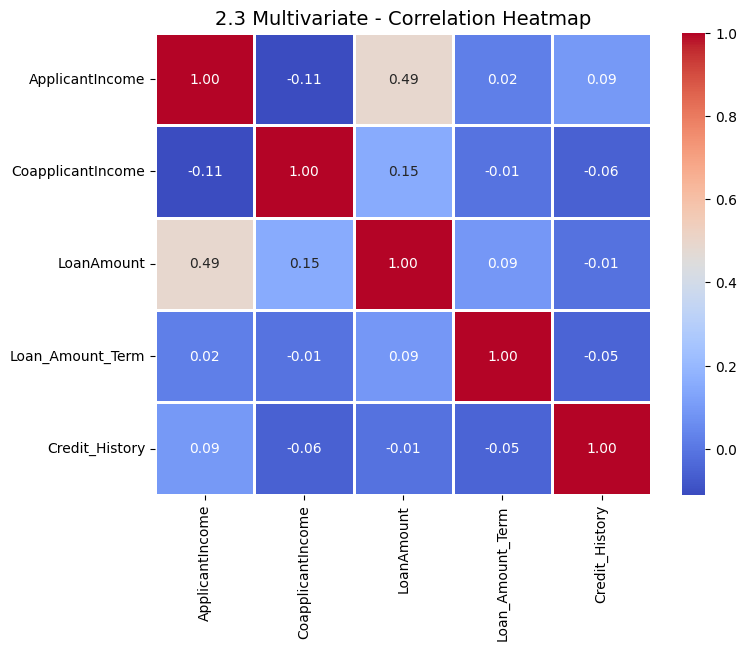

In [46]:
plt.figure(figsize=(8,6))
corr = df[['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=1)
plt.title('2.3 Multivariate - Correlation Heatmap', fontsize=14)
plt.show()


1. Correlation Heatmap:

The correlation heatmap shows that the highest correlation is between ApplicantIncome and LoanAmount (around 0.50-0.57), which is a moderate positive correlation. All other correlations are weak (0.1 to 0.2). Credit_History shows very low correlation with numerical variables as it is binary in nature.

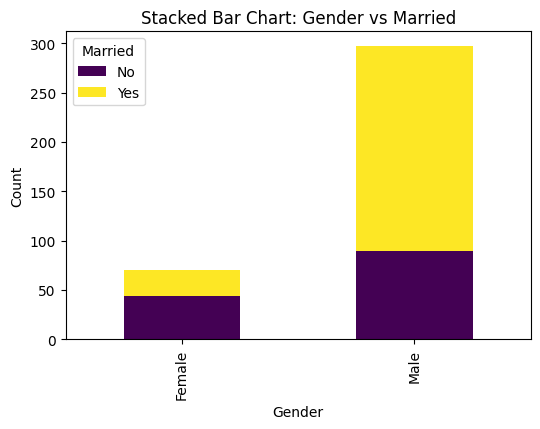

In [48]:
stacked_data = pd.crosstab(df['Gender'], df['Married'])
stacked_data.plot(kind='bar', stacked=True, figsize=(6,4), colormap='viridis')
plt.title('Stacked Bar Chart: Gender vs Married')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.legend(title='Married')
plt.show()


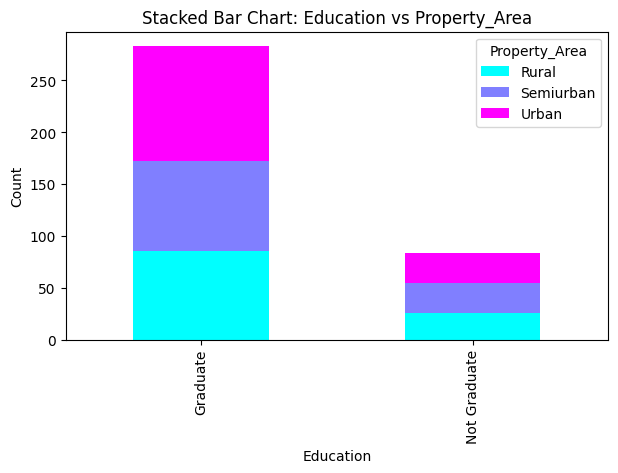

In [49]:
stacked_data2 = pd.crosstab(df['Education'], df['Property_Area'])
stacked_data2.plot(kind='bar', stacked=True, figsize=(7,4), colormap='cool')
plt.title('Stacked Bar Chart: Education vs Property_Area')
plt.xlabel('Education')
plt.ylabel('Count')
plt.legend(title='Property_Area')
plt.show()

. Stacked Bar Chart (Gender vs Married, Education vs Property_Area):

The stacked bar chart shows that among male applicants, the proportion of married individuals is higher. Female applicants have a more balanced married/unmarried ratio. In terms of Education vs Property_Area, graduates are mostly from Semiurban and Urban areas, while non-graduates have a slightly higher share in Rural areas.